In [1]:
# set up the working environment

import tensorflow as tf

from tensorflow.keras.layers import Embedding, GRU, Dense, Layer
from tensorflow.keras.layers import Concatenate, Add, LayerNormalization, Dropout
from tensorflow.keras.layers import MultiHeadAttention, AdditiveAttention
from tensorflow.keras.layers import TextVectorization, StringLookup
from tensorflow.keras import Sequential, Input, Model, callbacks, losses, optimizers

import time, os

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
print("Num GPUs Available:", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available: 1



# 1 The Data

We'll use an English-Chinese dataset provided by [Tab-delimited Bilingual Sentence Pairs](http://www.manythings.org/anki/). This dataset contains language translation pairs in the format below:

```
He called me a cab.	他替我叫了一部計程車。
```

## 1.1 Download and split the data

In [3]:
# download the file and return the absolute path as a string
path_to_file = tf.keras.utils.get_file('eng-chinese.txt', origin="https://raw.githubusercontent.com/justinjiajia/datafiles/master/eng-chinese.txt",
                                       cache_dir=".", cache_subdir="")
print("\nThe path to the downloaded file is:", path_to_file)

1269203/1269203 [==============================] - 0s 0us/step

The path to the downloaded file is: ./eng-chinese.txt


In [4]:
with open(path_to_file, "r") as f:
    # read all the text, and split it line by line
    list_of_lines = f.read().splitlines()

print("The first 10 lines:\n")

for idx, line in enumerate(list_of_lines):
    # show the first 10 lines
    if idx == 10: break
    print(line)

print(f"\nThere are {len(list_of_lines)} lines (tab-separated sentence pairs) in total.")

The first 10 lines:

Hi.	嗨。
Hi.	你好。
Run.	你用跑的。
Wait!	等等！
Hello!	你好。
I try.	让我来。
I won!	我赢了。
Oh no!	不会吧。
Cheers!	乾杯!
He ran.	他跑了。

There are 20289 lines (tab-separated sentence pairs) in total.


Next, we'll divide the paired sentences into two collections, one for each language:

In [5]:
pairs = [line.split('\t') for line in list_of_lines]

context_sentences = np.array([context for target, context in pairs])
target_sentences = np.array([target for target, context in pairs])

In [6]:
# the first 5 pairs
for i in range(5):
    print(context_sentences[i])
    print(target_sentences[i])
    print()

嗨。
Hi.

你好。
Hi.

你用跑的。
Run.

等等！
Wait!

你好。
Hello!



Next, we split these pairs of sentences into  training and validation sets, and create a `tf.data.Dataset` of strings in order to shuffle and batch them efficiently:

In [7]:
BUFFER_SIZE = len(list_of_lines)
BATCH_SIZE = 256

np.random.seed(42)

# a 90-10 split
is_train = np.random.uniform(size=len(list_of_lines)) < 0.9

train_text = (tf.data.Dataset.from_tensor_slices((context_sentences[is_train], target_sentences[is_train]))
              .shuffle(BUFFER_SIZE).batch(BATCH_SIZE))

val_text = (tf.data.Dataset.from_tensor_slices((context_sentences[~is_train], target_sentences[~is_train]))
            .shuffle(BUFFER_SIZE).batch(BATCH_SIZE))

In [8]:
# take one batch
for context_sentence_batch, target_sentence_batch in train_text.take(1):
    print(f"The number of examples in this batch is {len(context_sentence_batch)}.")
    print("\nThe first 4 source sentences and target sentences are:")
    print([context_sentence_example.numpy().decode() for context_sentence_example in context_sentence_batch[:4]])
    print([target_sentence_example.numpy().decode() for target_sentence_example in target_sentence_batch[:4]])
    break

The number of examples in this batch is 256.

The first 4 source sentences and target sentences are:
['讓我們找些可以坐在上面的東西。', '我丈夫一年收入10萬美元。', 'Tom的视力正在恶化。', '他不太关注棒球。']
["Let's find something to sit on.", 'My husband earns $100,000 a year.', "Tom's eyesight is deteriorating.", "He doesn't care much for baseball."]



<br>

## 1.2 Standardize the texts

We need to take several standardization steps to prepare our text data for training. These steps include removing special characters from both Chinese and English sentences and adding a start and end token to each of them.

In English, words are typically separated by spaces, making tokenizing English relatively straightforward. On the contrary, Chinese is a language that lacks clear delimiters between words. So, it is necessary to define two separate functions to preprocess English and Chinese sentences, respectively.


In [9]:
def eng_preprocess(text):

  # lowercase all characters
  text = tf.strings.lower(text)
  # keep space, a to z, and 0 to 9, and select punctuation
  text = tf.strings.regex_replace(text, '[^ a-z0-9.?!,"\']', ' ')
  # remove comma separators in numbers
  text =  tf.strings.regex_replace(text, r'(\d{1,3}),', r'\1')
  # add spaces around punctuation and numbers
  text = tf.strings.regex_replace(text, '[.?!,"\'0-9]', r' \0 ')
  # replace multiple spaces with one space
  text = tf.strings.regex_replace(text, '[ ]+', ' ')
  # strip whitespace
  text = tf.strings.strip(text)
  # prepend the start token and append the end token
  text = tf.strings.join(['[START]', text, '[END]'], separator=' ')

  return text

In [10]:
def chi_preprocess(text):

  # some sentences also contain English words
  text = tf.strings.lower(text)
  # add the space between non-English characters
  text = tf.strings.regex_replace(text, '[^a-z]', r' \0 ')
  # replace multiple spaces with one space
  text = tf.strings.regex_replace(text, '[ ]+', ' ')
  # replace several spaces with one space
  text = tf.strings.strip(text)
  # prepend the start token and append the end token
  text = tf.strings.join(['[START]', text, '[END]'], separator=' ')

  return text

Now that we have the two functions for text standardization ready, we'll apply them as part of text vectorization in a moment.


<br>

## 1.3 Build the vocabularies


Next, we'll use the `TextVectorization` API to handle the vocabulary extraction and conversion of input text to sequences of tokens. The two preprocessing functions we just defined will be baked into this process.

We first create a  `TextVectorization` layer to build the Chinese vocabulary:

In [11]:
context_text_processor = TextVectorization(standardize=chi_preprocess, ragged=True)

def remove_target(context, target):
  return context


# .adapt() reads the training data, and determines the vocabulary
context_text_processor.adapt(train_text.map(remove_target))


# get the vocabulary built by this layer
context_vocab = context_text_processor.get_vocabulary()

# here are the first 10 words from the vocabulary:
context_vocab[:10]

['', '[UNK]', '[START]', '[END]', '。', '我', '的', '了', '你', '他']

Now the layer can convert a batch of Chinese strings into a batch of token IDs:

In [12]:
print([context_sentence_example.numpy().decode() for context_sentence_example in context_sentence_batch[:4]], "\n")
context_tokens_batch = context_text_processor(context_sentence_batch)
context_tokens_batch[:4]

['讓我們找些可以坐在上面的東西。', '我丈夫一年收入10萬美元。', 'Tom的视力正在恶化。', '他不太关注棒球。'] 



<tf.RaggedTensor [[2, 129, 5, 21, 209, 93, 53, 56, 411, 12, 28, 210, 6, 259, 173, 4, 3],
 [2, 5, 1208, 628, 13, 83, 342, 407, 262, 177, 1177, 169, 449, 4, 3],
 [2, 236, 6, 510, 202, 132, 12, 2018, 1106, 4, 3],
 [2, 9, 10, 133, 438, 586, 505, 164, 4, 3]]>

Because there is no method available to the `TextVectorization` layer to perform index-to-word conversion, we want to create a "lookup" that is specialized to do so:

In [13]:
chi_idx_to_word = StringLookup(vocabulary=context_vocab,  mask_token='', oov_token='[UNK]', invert=True)

Once we get the lookup table, we can use it to convert token IDs back to text easily:

In [14]:
for context_tokens in chi_idx_to_word(context_tokens_batch[:4]):
    print([context_token.decode() for context_token in context_tokens.numpy()])

['[START]', '讓', '我', '們', '找', '些', '可', '以', '坐', '在', '上', '面', '的', '東', '西', '。', '[END]']
['[START]', '我', '丈', '夫', '一', '年', '收', '入', '1', '0', '萬', '美', '元', '。', '[END]']
['[START]', 'tom', '的', '视', '力', '正', '在', '恶', '化', '。', '[END]']
['[START]', '他', '不', '太', '关', '注', '棒', '球', '。', '[END]']


That's the Chinese `TextVectorization` layer, now build and `.adapt()` the English one:

In [15]:
target_text_processor = TextVectorization(standardize=eng_preprocess, ragged=True)

def remove_context(context, target):
    return target

target_text_processor.adapt(train_text.map(remove_context))
target_vocab = target_text_processor.get_vocabulary()

target_vocab[:10]

['', '[UNK]', '[START]', '[END]', '.', 'i', "'", 'the', 'to', 'you']

Likewise, this layer can convert a batch of English strings into a batch of token IDs:

In [16]:
print([target_sentence_example.numpy().decode() for target_sentence_example in target_sentence_batch[:4]], "\n")
target_tokens_batch = target_text_processor(target_sentence_batch)
target_tokens_batch[:4]

["Let's find something to sit on.", 'My husband earns $100,000 a year.', "Tom's eyesight is deteriorating.", "He doesn't care much for baseball."] 



<tf.RaggedTensor [[2, 83, 6, 19, 268, 145, 8, 719, 36, 4, 3],
 [2, 21, 870, 1784, 185, 109, 109, 109, 109, 109, 10, 193, 4, 3],
 [2, 15, 6, 19, 1301, 12, 5268, 4, 3],
 [2, 13, 108, 6, 14, 344, 114, 29, 447, 4, 3]]>

We also create an English "lookup table" to facilitate index-to-word conversion for English sentences:

In [17]:
eng_idx_to_word = StringLookup(vocabulary=target_vocab,  mask_token='', oov_token='[UNK]', invert=True)

In [18]:
for target_tokens in eng_idx_to_word(target_tokens_batch[:4]):
    print([target_token.decode() for target_token in target_tokens.numpy()])

['[START]', 'let', "'", 's', 'find', 'something', 'to', 'sit', 'on', '.', '[END]']
['[START]', 'my', 'husband', 'earns', '1', '0', '0', '0', '0', '0', 'a', 'year', '.', '[END]']
['[START]', 'tom', "'", 's', 'eyesight', 'is', 'deteriorating', '.', '[END]']
['[START]', 'he', 'doesn', "'", 't', 'care', 'much', 'for', 'baseball', '.', '[END]']


Here are the sizes of the two vocabularies:

In [19]:
print("The vocabulary size of the source language:", len(context_vocab))
print("The vocabulary size of the target language:", len(target_vocab))

The vocabulary size of the source language: 3361
The vocabulary size of the target language: 5855



Recall that the sequences in our dataset still have varying lengths.

To ensure a uniform length across sequences in the same batch, we simply use `.to_tensor()` to convert ragged tensors to normal tensors. As a result, each element in a `RaggedTensor` will be automatically zero-padded to the length of the longest sequence within the batch.

In [20]:
print(f"The shape of this batch is: {context_tokens_batch.to_tensor().shape}")
print(f"\nAll sequences are zero-padded to have the same length:\n{context_tokens_batch.to_tensor()[:4]}")

The shape of this batch is: (256, 38)

All sequences are zero-padded to have the same length:
[[   2  129    5   21  209   93   53   56  411   12   28  210    6  259
   173    4    3    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0]
 [   2    5 1208  628   13   83  342  407  262  177 1177  169  449    4
     3    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0]
 [   2  236    6  510  202  132   12 2018 1106    4    3    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0]
 [   2    9   10  133  438  586  505  164    4    3    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0]]



<br>

## 1.4 Tokenize the data

Remember that we only performed tokenization and standardization on 1 batch of source sentences and 1 batch of target sentences.

Next, let's extend it to all paired sequences in our data.

The `process_text` function below is defined to package two steps we need to take for each pair of sequences:

 - Converts the `Datasets` of strings into  0-padded tensors of token IDs;
 - Converts  a `(context, target)` pair to an `((context, target_in), target_out)` pair for training with `keras.Model.fit`.

 > Keras expects `(inputs, labels)` pairs, the inputs are the `(context, target_in)` and the labels are `target_out`. The difference between `target_in` and `target_out` is that they are shifted by one step relative to each other, so that at each location the label is the next token.


In [21]:
def process_text(context, target):
    context = context_text_processor(context).to_tensor()
    target = target_text_processor(target)
    target_in = target[:, :-1].to_tensor()
    target_out = target[:, 1:].to_tensor()
    return (context, target_in), target_out

train_ds = train_text.map(process_text, tf.data.AUTOTUNE)
val_ds = val_text.map(process_text, tf.data.AUTOTUNE)

We can print the shapes of the context sequences, the target  input sequences, and the target  output sequences in the first several batches to get an idea of how they are organized and vary across batches:

In [22]:
for (context_batch, target_in_batch), target_out_batch in train_ds.take(4):
  print(context_batch.shape)
  print(target_in_batch.shape)
  print(target_out_batch.shape, "\n")

(256, 23)
(256, 18)
(256, 18) 

(256, 24)
(256, 17)
(256, 17) 

(256, 24)
(256, 15)
(256, 15) 

(256, 25)
(256, 19)
(256, 19) 



And here is the first 4 sequence of each, from the first batch:

In [23]:
for (context_batch, target_in_batch), target_out_batch in train_ds.take(1):
    print(f"The first 4 context sentences:\n{context_batch[:4].numpy()}")
    # target_in starts with [START]
    print(f"\nThe first 4 input sentences in the target language:\n{target_in_batch[:4].numpy()}")
    # target_out ends with [END]
    print(f"\nThe first 4 output sentences:\n{target_out_batch[:4].numpy()}")

The first 4 context sentences:
[[   2  264  201    5 1119   13 1119    4    3    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0]
 [   2    9    6  499 1717  202  538  201    5   84  732    4    3    0
     0    0    0    0    0    0    0    0    0    0    0    0    0]
 [   2    9  599    9    6  100  375 1854  375  308   34  809    4    3
     0    0    0    0    0    0    0    0    0    0    0    0    0]
 [   2   40   16  638  151   74   27  393 1105    4    3    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0]]

The first 4 input sentences in the target language:
[[   2   59  229   23  354    4    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0]
 [   2   37 1194  141 5537    8 3444   23    4    0    0    0    0    0
     0    0    0    0    0    0    0]
 [   2   13 5695   37  621    8   65  865    4    0    0    0    0    0
     0    0    0    0    0    0    0]
 [   2   15   12   36    

---

<br>

# 2 Build the model


There's a lot going on inside a Transformer. Let's work through it step by step:





## 2.1 Positional Encoding



Since the model doesn't contain any recurrent layers, the attention layers used throughout the model see their input as a set of vectors without order.  It needs some way to identify word order.

A Transformer adds a "Positional Encoding" to the embedding vectors to inject the order information.

To do so, we define a positional encoding function, which is a stack of sines and cosines that vibrate at different frequencies depending on their location.

In [24]:
def positional_encoding(length, depth):

    depth = depth / 2

    positions = np.arange(length)[:, np.newaxis]       # (num_steps, 1)
    depths = np.arange(depth)[np.newaxis, :] / depth   # (1, depth); depth = size of each word vector / 2 due to the first step

    angle_rates = 1 / (10000 ** depths)                # (1, depth)
    angle_rads = positions * angle_rates               # (num_steps, depth)

    # concatenate the sines and cosines; now the size of each position vector == that of each word vector
    pos_encoding = np.concatenate([np.sin(angle_rads), np.cos(angle_rads)], axis=-1)

    return tf.cast(pos_encoding, dtype=tf.float32)

We can try it out and visualize the resulting position vectors. You'll find that they are all distinct.

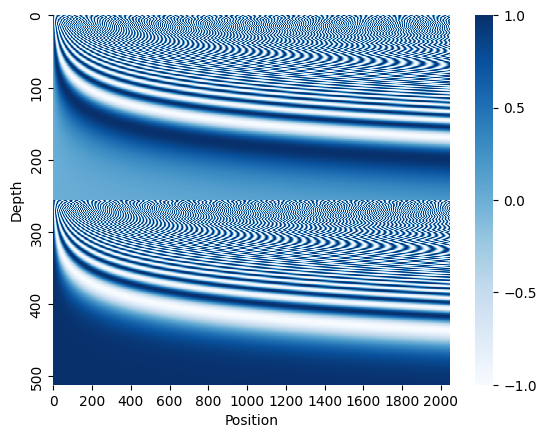

In [25]:
# generate 2048 position vectors, each of length 512

pos_encoding = positional_encoding(length=2048, depth=512)

# plot the vectors
ax = sns.heatmap(pos_encoding.numpy().T, cmap='Blues', xticklabels=200, yticklabels=100,
                 cbar_kws={"ticks": np.arange(-1, 1.1, 0.5)})
ax.set(xlabel='Position', ylabel='Depth')
plt.show()

Next, we define a custom `Embedding` layer that looks up a token's embedding vector and adds the position vector:

In [26]:
class PositionalEmbedding(Layer):
    def __init__(self, vocab_size, d_model):
        super().__init__()
        self.d_model = d_model
        # mask_zero=True: whether to treat the input value 0 as a special "padding" value so as to mask it out
        self.embedding = Embedding(vocab_size, d_model, mask_zero=True)
        self.pos_encoding = positional_encoding(length=2048, depth=d_model)

    def compute_mask(self, *args, **kwargs):
        # implement layer.compute_mask() method for this custom layer to produce input masks https://www.tensorflow.org/guide/keras/understanding_masking_and_padding#supporting_masking_in_your_custom_layers
        return self.embedding.compute_mask(*args, **kwargs)   # https://github.com/keras-team/keras/blob/v2.14.0/keras/layers/core/embedding.py#L189

    def call(self, x):
        length = tf.shape(x)[1]
        x = self.embedding(x)
        # This factor sets the relative scale of the embedding and positonal_encoding.
        x *= tf.math.sqrt(tf.cast(self.d_model, tf.float32))
        x = x + self.pos_encoding[tf.newaxis, :length, :]
        return x


In [27]:
embed_chi = PositionalEmbedding(vocab_size=context_text_processor.vocabulary_size(), d_model=512)
embed_eng = PositionalEmbedding(vocab_size=target_text_processor.vocabulary_size(), d_model=512)

chi_emb = embed_chi(context_batch)
eng_emb = embed_eng(target_in_batch)

You can run the following code to see how input masks generated automatically match the non-padding steps in both context sentences and target sentences:

In [28]:
# this layer has generated desired input masks due to the implementation of compute_mask()
# the generated masks can be accessed via the ._keras_mask attribute
chi_emb._keras_mask

<tf.Tensor: shape=(256, 27), dtype=bool, numpy=
array([[ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False],
       ...,
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False]])>

In [29]:
eng_emb._keras_mask

<tf.Tensor: shape=(256, 21), dtype=bool, numpy=
array([[ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False],
       ...,
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False]])>

In [30]:
# the number of non-padding tokens in each context sequence
(context_batch.numpy() != 0).sum(axis=-1)

array([ 9, 13, 14, 11, 13, 11, 11,  9,  8, 11, 16,  8,  9, 13,  8, 12, 14,
       10, 15,  9, 10,  8,  9, 15, 15, 12, 17, 13, 13,  9, 16,  8, 11, 13,
       14,  9, 14, 10, 12,  8, 18, 10, 11, 10, 11, 20,  7, 15, 14, 11, 16,
       16, 20, 13, 12, 19,  9, 14, 15,  7, 16, 11, 10, 10,  8,  8, 14, 13,
       15,  5, 11, 13,  9, 14, 12, 15, 14, 23, 10, 11, 11,  8, 12, 10, 12,
       12, 16,  9, 10, 13,  6, 10,  9, 12, 14, 13, 11, 11, 15, 11,  9, 10,
       13, 11, 10, 14, 13,  8, 12, 13, 11, 27,  7, 13, 11, 13,  7,  9, 13,
       11, 11, 21, 11,  9, 10, 12, 12, 14, 20, 14, 11, 17, 19, 10, 15, 13,
        9, 12, 10, 14,  8,  9, 13, 11, 15, 12, 11, 12, 11, 12, 13, 11,  9,
        8, 14,  9,  9, 14, 14,  9, 12, 14, 16,  9, 11, 14, 15, 10,  7, 15,
       10, 11, 11,  6, 10, 16, 12,  9, 11,  6, 10, 11, 13,  7, 15,  7, 12,
       11,  9, 11, 12, 11, 11, 11, 10, 13, 15, 13, 12,  9, 14, 11,  9, 12,
       16, 12, 12,  7, 15, 13, 12, 14, 10, 13,  9, 12, 14, 10,  8, 11, 10,
       13, 15, 12, 12, 12

In [31]:
# the number of non-padding tokens in each target sequence
(target_in_batch.numpy() != 0).sum(axis=-1)

array([ 6,  9,  9, 10, 10,  7,  7,  9,  7,  7, 14,  8,  5,  9,  8,  8,  9,
        9, 10,  5, 11,  7,  6,  9, 10,  7,  9, 15,  8,  4, 10,  6,  9,  8,
        8,  6, 12,  9,  9,  9, 11, 11,  8,  9,  8,  8,  7, 11, 11,  5, 10,
       15, 18,  7,  9, 11,  8, 10, 12,  5,  9, 10,  8, 10,  6,  6, 11, 10,
        9,  4,  8,  9, 10, 11, 11,  9, 12, 21,  8,  9,  9,  6,  9,  8,  8,
       11, 14,  8,  9, 13,  5,  9,  7,  7,  7, 10,  9,  9, 11,  6,  6, 10,
       14,  8, 10,  9,  7,  6,  8,  9,  6, 15,  7,  9,  7,  8,  8,  9,  8,
        9,  7, 12,  8,  8,  8, 12,  7, 10, 16, 11, 11, 14, 13,  8,  9,  9,
        6,  8,  9,  9,  8,  9,  7,  9, 12, 11, 11,  8,  7, 10,  9,  8,  7,
        8,  9,  8,  8,  8, 10, 10,  6,  9, 11,  6,  8, 11, 15,  6,  9,  8,
       10,  8,  6,  7,  9, 11,  8,  6,  8,  5,  6,  7,  9,  6,  9,  8,  8,
        9,  6,  8, 11,  7,  6,  6,  8,  9,  7,  8,  9,  7, 11,  9,  9,  7,
       10,  9,  7,  5, 10, 11,  9,  9,  9,  9, 10,  9, 11,  9,  8, 12,  8,
       11, 12, 13, 12, 11

In [32]:
# the number of True's equals the number of the non-padding tokens in the corresponding context sequence
chi_emb._keras_mask.numpy().sum(axis=-1)

array([ 9, 13, 14, 11, 13, 11, 11,  9,  8, 11, 16,  8,  9, 13,  8, 12, 14,
       10, 15,  9, 10,  8,  9, 15, 15, 12, 17, 13, 13,  9, 16,  8, 11, 13,
       14,  9, 14, 10, 12,  8, 18, 10, 11, 10, 11, 20,  7, 15, 14, 11, 16,
       16, 20, 13, 12, 19,  9, 14, 15,  7, 16, 11, 10, 10,  8,  8, 14, 13,
       15,  5, 11, 13,  9, 14, 12, 15, 14, 23, 10, 11, 11,  8, 12, 10, 12,
       12, 16,  9, 10, 13,  6, 10,  9, 12, 14, 13, 11, 11, 15, 11,  9, 10,
       13, 11, 10, 14, 13,  8, 12, 13, 11, 27,  7, 13, 11, 13,  7,  9, 13,
       11, 11, 21, 11,  9, 10, 12, 12, 14, 20, 14, 11, 17, 19, 10, 15, 13,
        9, 12, 10, 14,  8,  9, 13, 11, 15, 12, 11, 12, 11, 12, 13, 11,  9,
        8, 14,  9,  9, 14, 14,  9, 12, 14, 16,  9, 11, 14, 15, 10,  7, 15,
       10, 11, 11,  6, 10, 16, 12,  9, 11,  6, 10, 11, 13,  7, 15,  7, 12,
       11,  9, 11, 12, 11, 11, 11, 10, 13, 15, 13, 12,  9, 14, 11,  9, 12,
       16, 12, 12,  7, 15, 13, 12, 14, 10, 13,  9, 12, 14, 10,  8, 11, 10,
       13, 15, 12, 12, 12

In [33]:
# the number of True's equals the number of the non-padding tokens in the corresponding target sequence
eng_emb._keras_mask.numpy().sum(axis=-1)

array([ 6,  9,  9, 10, 10,  7,  7,  9,  7,  7, 14,  8,  5,  9,  8,  8,  9,
        9, 10,  5, 11,  7,  6,  9, 10,  7,  9, 15,  8,  4, 10,  6,  9,  8,
        8,  6, 12,  9,  9,  9, 11, 11,  8,  9,  8,  8,  7, 11, 11,  5, 10,
       15, 18,  7,  9, 11,  8, 10, 12,  5,  9, 10,  8, 10,  6,  6, 11, 10,
        9,  4,  8,  9, 10, 11, 11,  9, 12, 21,  8,  9,  9,  6,  9,  8,  8,
       11, 14,  8,  9, 13,  5,  9,  7,  7,  7, 10,  9,  9, 11,  6,  6, 10,
       14,  8, 10,  9,  7,  6,  8,  9,  6, 15,  7,  9,  7,  8,  8,  9,  8,
        9,  7, 12,  8,  8,  8, 12,  7, 10, 16, 11, 11, 14, 13,  8,  9,  9,
        6,  8,  9,  9,  8,  9,  7,  9, 12, 11, 11,  8,  7, 10,  9,  8,  7,
        8,  9,  8,  8,  8, 10, 10,  6,  9, 11,  6,  8, 11, 15,  6,  9,  8,
       10,  8,  6,  7,  9, 11,  8,  6,  8,  5,  6,  7,  9,  6,  9,  8,  8,
        9,  6,  8, 11,  7,  6,  6,  8,  9,  7,  8,  9,  7, 11,  9,  9,  7,
       10,  9,  7,  5, 10, 11,  9,  9,  9,  9, 10,  9, 11,  9,  8, 12,  8,
       11, 12, 13, 12, 11

## 2.2 Attention


A variety of attention layers are used throughout the Transformer architecture.

They all contain a [`MultiHeadAttention` layer](https://www.tensorflow.org/api_docs/python/tf/keras/layers/MultiHeadAttention), a `LayerNormalization` layer, and an `Add` layer for adding a residual connection.  

To implement these attention layers, we start with a simple base class that just contains these component layers. Different attention patterns, including self-attention, cross-attention, and masked attention, will later be implemented as a subclass.

In [34]:
class BaseAttention(Layer):
    def __init__(self, **kwargs):
        super(BaseAttention, self).__init__()
        self.mha = MultiHeadAttention(**kwargs)
        self.layernorm = LayerNormalization()
        self.add = Add()

### 2.2.1 The cross attention layer


At the literal center of the Transformer is the cross-attention layer, which connects the encoder and decoder:

In [35]:
class CrossAttention(BaseAttention):

    def call(self, x, context):
        # x is the vector extracted by the decoder
        # both key and value are the context vector extracted by the encoder
        # attn_output is of the same size as x;  recall: the last component of a multi-head attention block is a linear layer that ensures this
        attn_output, attn_scores = self.mha(query=x, key=context, value=context,
                                            return_attention_scores=True)
        self.last_attn_scores = attn_scores

        x = self.add([x, attn_output])
        x = self.layernorm(x)

        return x

In [37]:
# key_dim specifies the size for query vectors and key vectors
# if value_dim is not specified, value vectors are also of the same size
# reference: https://github.com/keras-team/keras/blob/v2.14.0/keras/layers/attention/multi_head_attention.py#L256 self._value_dim = value_dim if value_dim else key_dim
sample_cross_attention = CrossAttention(num_heads=3, key_dim=256)

print("the shape of vector representations extracted in encoder:", chi_emb.shape)
print("the shape of vector representations extracted in decoder:", eng_emb.shape)

# shape: (batch_size, num_decoder_steps, num_units)
print("the shape of the outputs of a multi-head attention layer:", sample_cross_attention(eng_emb, chi_emb,).shape)

# shape: (batch_size, num_heads, num_decoder_steps, num_encoder_steps)
print("the shape of multi-head attention weights:", sample_cross_attention.last_attn_scores.shape)

the shape of vector representations extracted in encoder: (256, 27, 512)
the shape of vector representations extracted in decoder: (256, 21, 512)
the shape of the outputs of a multi-head attention layer: (256, 21, 512)
the shape of multi-head attention weights: (256, 3, 21, 27)


Run the following code to see how many parameters are used by this multi-head attention block:



In [38]:
[(w.name, w.shape) for w in sample_cross_attention.weights]

[('cross_attention_1/multi_head_attention_1/query/kernel:0',
  TensorShape([512, 3, 256])),
 ('cross_attention_1/multi_head_attention_1/query/bias:0',
  TensorShape([3, 256])),
 ('cross_attention_1/multi_head_attention_1/key/kernel:0',
  TensorShape([512, 3, 256])),
 ('cross_attention_1/multi_head_attention_1/key/bias:0',
  TensorShape([3, 256])),
 ('cross_attention_1/multi_head_attention_1/value/kernel:0',
  TensorShape([512, 3, 256])),
 ('cross_attention_1/multi_head_attention_1/value/bias:0',
  TensorShape([3, 256])),
 ('cross_attention_1/multi_head_attention_1/attention_output/kernel:0',
  TensorShape([3, 256, 512])),
 ('cross_attention_1/multi_head_attention_1/attention_output/bias:0',
  TensorShape([512])),
 ('cross_attention_1/layer_normalization_1/gamma:0', TensorShape([512])),
 ('cross_attention_1/layer_normalization_1/beta:0', TensorShape([512]))]

#### Question 1

> Edit this markdown cell to explain what the parameters above are used for and why they have their corresponding shapes.

In simple why the number of each parameter is 512, 256 and 3

512 is the hidden size or the number of units in the hidden layer of the attention mechanism. 256 is the vector that value each context of the words. 3 is the number of attention head

- In the encoder, it is (256, 21, 512) meaning that there is 256 context for each of 21 words in a processing of 512 hidden layer. 21 comes from chi_emb.

- In the decoder, it is (256, 19, 512) meaning that there is 256 context for each of 19 words in a processing of 512 hidden layer. 19 comes from eng_emb.

- The outputs has the same size dimension as decoder.



---


> ('cross_attention/multi_head_attention/query/kernel:0',
  TensorShape([512, 3, 256]))
- Quary Paramters: Its function is to transform input sequence into query vectors. It has corresponding shape because of [num_units, num_heads, key_dim]. Num_unit is the input, each of them has num_heads * key_dim which is the query vectors.

> ('cross_attention/multi_head_attention/key/kernel:0',
  TensorShape([512, 3, 256]))
- Key Parameters: Similar to the query parameters,it is used to transform the context sequence (from the encoder) into key vectors. The dimensions are aligned to enable dot-product attention between queries and keys

>  ('cross_attention/multi_head_attention/value/kernel:0',
  TensorShape([512, 3, 256]))
- Value Parameters: The value vectors represent the actual content or information from the input that will be attended to based on the attention scores computed between the queries and keys. The shape is [num_units, num_heads * value_dim]
<br>
if value_dim is not specified, value vectors are also of the same size as key_dims
<br>
reference: https://github.com/keras-team/keras/blob/v2.14.0/keras/layers/attention/multi_head_attention.py#L256 <br>  self._value_dim = value_dim if value_dim else key_dim


> ('cross_attention/multi_head_attention/attention_output/kernel:0',
  TensorShape([3, 256, 512]))
- Output Parameter: After computing attention for each attention head, the results from different heads are concatenated and then projected back to the original embedding dimension using a projection layer. The weights of this projection layer have a shape of [num_heads * key_dims, num_units].

> ('cross_attention/multi_head_attention/query/bias:0', TensorShape([3, 256]))
- Bias Parameter:  For each of the above linear transformations (Query, Key, Value, and Output), there's a corresponding bias term to add flexibility to the model. the bias for the query weights would have a shape of [num_heads * key_dim] because bias term is broadcasted across the attention outputs of each head during the projection step.

>  ('cross_attention/layer_normalization/gamma:0', TensorShape([512])),
<br>
('cross_attention/layer_normalization/beta:0', TensorShape([512]))
- Normlization Layer: It represents the scaling factor for the layer normalization operation. it has the dimension same as the number of units/ hidden layer which is [512]

### 2.2.2 The global self-attention layer


Because the self-attention pattern used for extracting representations in the encoder portion can access the entire sequence of inputs, we can call it the global self-attention.


To implement this layer, we only need to supply the target sequence, `x`, as the `query`, `key`, and `value` arguments to the `mha` layer:



In [ ]:
class GlobalSelfAttention(BaseAttention):
      def call(self, x):
          attn_output = self.mha(query=x, value=x, key=x)
          x = self.add([x, attn_output])
          x = self.layernorm(x)
          return x

In [ ]:
sample_global_self_attention = GlobalSelfAttention(num_heads=3, key_dim=256)

print("the shape of vector representations extracted in encoder:", chi_emb.shape)
# shape:  (batch_size, num_encoder_steps, num_units)
print("the shape of the outputs of a multi-head attention layer:", sample_global_self_attention(chi_emb).shape)

the shape of vector representations extracted in encoder: (256, 21, 512)
the shape of the outputs of a multi-head attention layer: (256, 21, 512)


### 2.2.3 The causal self attention layer

To prevent the attention head from simply copying over future words as predictions during training,  we need to use masked self-attention or causal self-attention, where we apply a causal mask to prevent the head from attending to future words.

Appropriate masks can be automatically generated if we pass `use_causal_mask = True` to the MultiHeadAttention layer when we call it:

In [ ]:
class CausalSelfAttention(BaseAttention):
    def call(self, x):
        # use_causal_mask=True: a boolean to indicate whether to apply a causal mask to prevent the head from attending to future tokens
        attn_output = self.mha(query=x, value=x, key=x, use_causal_mask=True)
        x = self.add([x, attn_output])
        x = self.layernorm(x)
        return x

In [ ]:
sample_causal_self_attention = CausalSelfAttention(num_heads=3, key_dim=256)


print("the shape of vector representations extracted in encoder:", eng_emb.shape)
# shape: (batch_size, num_decoder_steps, num_units)
print("the shape of the outputs of a multi-head attention layer:", sample_causal_self_attention(eng_emb).shape)

the shape of vector representations extracted in encoder: (256, 19, 512)
the shape of the outputs of a multi-head attention layer: (256, 19, 512)



## 2.3 The feed forward network

To inject desired non-linearities, we also need to include point-wise feed-forward networks to postprocess the outputs of attention layers in both the encoder and decoder.




#### Question 2

Complete the code below to implement the point-wise feed-forward network.

Hint: you can refer to the slides for what computations you need to implementn here.

In [ ]:
class FeedForward(Layer):
    def __init__(self, d_model, dff):
        super().__init__()

        self.w1 = Dense(dff, activation='relu')
        self.w2 = Dense(d_model)

        self.add = Add()
        self.layer_norm = LayerNormalization()

    def call(self, x):
        x_ffn = self.w1(x)
        x_ffn = self.w2(x_ffn)
        x = self.add([x, x_ffn])
        x = self.layer_norm(x)

        return x


## 2.4 The encoder block


The encoder of the transformer architecture contains a stack of $N$ encoder blocks, which each contain a `GlobalSelfAttention` and `FeedForward` layer::

In [ ]:
class EncoderBlock(Layer):
    def __init__(self, *, d_model, num_heads, dff, dropout_rate=0.1):
        super(EncoderBlock, self).__init__()

        self.self_attention = GlobalSelfAttention(num_heads=num_heads,
                                                  key_dim=d_model,
                                                  dropout=dropout_rate)

        self.ffn = FeedForward(d_model, dff)

    def call(self, x):
        x = self.self_attention(x)
        x = self.ffn(x)
        return x

## 2.5 The encoder

Next, we build the encoder, which consists of a `PositionalEmbedding` layer at the input, and a stack of `EncoderBlock`s:



In [ ]:
class Encoder(Layer):
    def __init__(self, *, num_layers, d_model, num_heads, dff, vocab_size, dropout_rate=0.1):
        super(Encoder, self).__init__()

        self.d_model = d_model
        self.num_layers = num_layers
        self.pos_embedding = PositionalEmbedding(vocab_size=vocab_size, d_model=d_model)

        self.encoder_layer = [EncoderBlock(d_model=d_model, num_heads=num_heads, dff=dff, dropout_rate=dropout_rate) for _ in range(num_layers)]

        self.dropout = Dropout(dropout_rate)

    def call(self, x):
        x = self.pos_embedding(x)
        x = self.dropout(x)

        for i in range(self.num_layers):
            x = self.encoder_layer[i](x)

        return x

Try it out:

In [ ]:
# instantiate the encoder.
sample_encoder = Encoder(num_layers=4, d_model=512,  num_heads=8, dff=2048, vocab_size=8500)

sample_encoder_output = sample_encoder(context_batch)

# print the shape
print(context_batch.shape)

# shape: (batch_size, num_encoder_steps, d_model)
print(sample_encoder_output.shape)

(256, 21)
(256, 21, 512)


## 2.6 The decoder block

The decoder of the transformer architecture also contains a stack of $N$ decoder blocks, which each contain a `CausalSelfAttention`, a `CrossAttention`, and a `FeedForward` layer:

In [ ]:
class DecoderBlock(Layer):
    def __init__(self, *, d_model, num_heads, dff, dropout_rate=0.1):
        super().__init__()

        self.causal_self_attention = CausalSelfAttention(num_heads=num_heads, key_dim=d_model,
                                                         dropout=dropout_rate)

        self.cross_attention = CrossAttention(num_heads=num_heads, key_dim=d_model,
                                              dropout=dropout_rate)

        self.ffn = FeedForward(d_model, dff)

    def call(self, x, context):
        x = self.causal_self_attention(x)
        x = self.cross_attention(x, context)

        # cache the last attention scores for plotting later
        self.last_attn_scores = self.cross_attention.last_attn_scores
        x = self.ffn(x)
        return x

## 2.7 The decoder


Similar to the `Encoder`, the `Decoder` consists of a `PositionalEmbedding`, and a stack of `DecoderBlock`s.

#### Question 3

Complete the code below to implement the computations needed for the decoder:

In [ ]:
class Decoder(Layer):
    def __init__(self, *, num_layers, d_model, num_heads, dff, vocab_size, dropout_rate=0.1):
        super().__init__()

        self.d_model = d_model
        self.num_layers = num_layers

        self.pos_embedding = PositionalEmbedding(vocab_size=vocab_size,
                                                 d_model=d_model)
        self.dropout = Dropout(dropout_rate)
        self.decoder_layer = [DecoderBlock(d_model=d_model, num_heads=num_heads, dff=dff, dropout_rate=dropout_rate) for _ in range(num_layers)]

    def call(self, x, context):
        
        x = self.pos_embedding(x)
        x = self.dropout(x)

        for i in range(self.num_layers):
          x = self.decoder_layer[i](x, context)

        self.last_attn_scores = self.decoder_layer[-1].last_attn_scores
        

        return x

Try it out:


In [ ]:
# instantiate the decoder.
sample_decoder = Decoder(num_layers=4, d_model=512, num_heads=8, dff=2048, vocab_size=8000)

sample_decoder_output = sample_decoder(target_in_batch, chi_emb)

# print the shapes
print(target_in_batch.shape)

# shape: (batch_size, num_decoder_steps, d_model)
print(sample_decoder_output.shape)

# shape: (batch_size, num_heads, num_decoder_steps, num_encoder_steps)
print(sample_decoder.last_attn_scores.shape)

(256, 19)
(256, 19, 512)
(256, 8, 19, 21)


## 2.8  The Transformer



To complete the Transformer model, we need to put them together and add a final linear (`Dense`) layer, which converts the resulting vector at each location into output probabilities:

In [ ]:
class Transformer(Model):

    @classmethod
    def add_method(cls, fun):
      setattr(cls, fun.__name__, fun)
      return fun

    def __init__(self, num_layers, d_model, num_heads, dff, context_vocab_size, target_vocab_size, dropout_rate=0.1):
        super().__init__()
        self.encoder = Encoder(num_layers=num_layers, d_model=d_model, num_heads=num_heads, dff=dff,
                               vocab_size=context_vocab_size, dropout_rate=dropout_rate)

        self.decoder = Decoder(num_layers=num_layers, d_model=d_model, num_heads=num_heads, dff=dff,
                               vocab_size=target_vocab_size, dropout_rate=dropout_rate)

        self.final_layer = Dense(target_vocab_size)

    def call(self, inputs):
        # recall: each batch in tf.data.Dataset is oraganized into a tuple of the form ((context, target_in), target_out)
        # so, inputs is a tuple of the form (context, target_in)
        context, x = inputs

        context = self.encoder(context)
        x = self.decoder(x, context)
        logits = self.final_layer(x)

        try:
            del logits._keras_mask
        except AttributeError: pass
        return logits


Now we can instantiate the transformer with the following hyperparameters:

In [ ]:
# here are some hyperparameters to use
num_layers = 4
d_model = 128
dff = 512
num_heads = 8
dropout_rate = 0.1


transformer = Transformer(num_layers, d_model, num_heads, dff,
                          context_text_processor.vocabulary_size(), target_text_processor.vocabulary_size(),
                          dropout_rate)

Try it out:

In [ ]:
output = transformer((context_batch, target_in_batch))

print(output.shape)

(256, 19, 5855)


Also print the model summary:

In [ ]:
transformer.summary()

Model: "transformer"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 encoder_1 (Encoder)         multiple                  3069056   
                                                                 
 decoder_1 (Decoder)         multiple                  5499264   
                                                                 
 dense_32 (Dense)            multiple                  755295    
                                                                 
Total params: 9323615 (35.57 MB)
Trainable params: 9323615 (35.57 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


---

<br>

#  3  Train the model

It's time to prepare the model and start training it.

## 3.1 Set up the optimizer

Use the Adam optimizer with a custom learning rate scheduler according to the formula in the original Transformer paper.

In [ ]:
class CustomSchedule(optimizers.schedules.LearningRateSchedule):
    def __init__(self, d_model, warmup_steps=4000):
        super().__init__()

        self.d_model = d_model
        self.d_model = tf.cast(self.d_model, tf.float32)

        self.warmup_steps = warmup_steps

    def __call__(self, step):
        step = tf.cast(step, dtype=tf.float32)
        arg1 = tf.math.rsqrt(step)
        arg2 = step * (self.warmup_steps ** -1.5)

        return tf.math.rsqrt(self.d_model) * tf.math.minimum(arg1, arg2)

Instantiate the optimizer:

In [ ]:
learning_rate = CustomSchedule(d_model)

optimizer = optimizers.Adam(learning_rate, beta_1=0.9, beta_2=0.98, epsilon=1e-9)

Test the custom learning rate scheduler:

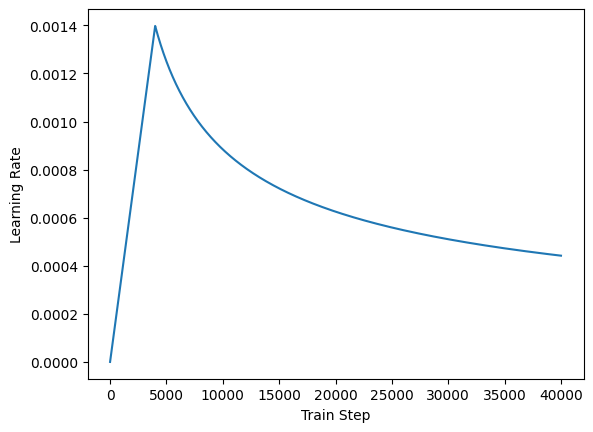

In [ ]:
plt.plot(learning_rate(tf.range(40000, dtype=tf.float32)))
plt.ylabel('Learning Rate')
plt.xlabel('Train Step')
plt.show()

## 3.2 Set up the loss and metrics

Since the target sequences are padded, it is important to apply a padding mask when calculating the loss.

In [ ]:
def masked_loss(label, pred):
    mask = label != 0
    loss_object = losses.SparseCategoricalCrossentropy(from_logits=True, reduction='none')
    loss = loss_object(label, pred)

    mask = tf.cast(mask, dtype=loss.dtype)
    loss *= mask

    loss = tf.reduce_sum(loss)/tf.reduce_sum(mask)
    return loss


def masked_accuracy(label, pred):
    pred = tf.argmax(pred, axis=2)
    label = tf.cast(label, pred.dtype)
    is_match = label == pred

    mask = label != 0

    is_match = is_match & mask

    is_match = tf.cast(is_match, dtype=tf.float32)
    mask = tf.cast(mask, dtype=tf.float32)
    return tf.reduce_sum(is_match)/tf.reduce_sum(mask)

## 3.3 Train the model


With all the components ready, configure the training procedure using `.compile()`, and then run it with `.fit()`:

In [ ]:
transformer.compile(optimizer=optimizer, loss=masked_loss, metrics=[masked_accuracy])


In [ ]:
# approximately 20 seconds per epoch with a GPU

history = transformer.fit(train_ds, epochs=50, validation_data=val_ds,
                          callbacks=[callbacks.EarlyStopping(patience=3, restore_best_weights=True)])

Epoch 1/50
72/72 [==============================] - 63s 352ms/step - loss: 8.4538 - masked_accuracy: 0.0721 - val_loss: 8.1930 - val_masked_accuracy: 0.1123
Epoch 2/50
72/72 [==============================] - 20s 273ms/step - loss: 7.9690 - masked_accuracy: 0.1457 - val_loss: 7.6749 - val_masked_accuracy: 0.2244
Epoch 3/50
72/72 [==============================] - 20s 280ms/step - loss: 7.3345 - masked_accuracy: 0.2267 - val_loss: 6.9574 - val_masked_accuracy: 0.2336
Epoch 4/50
72/72 [==============================] - 19s 267ms/step - loss: 6.5682 - masked_accuracy: 0.2419 - val_loss: 6.1616 - val_masked_accuracy: 0.2713
Epoch 5/50
72/72 [==============================] - 19s 264ms/step - loss: 5.7916 - masked_accuracy: 0.3083 - val_loss: 5.4419 - val_masked_accuracy: 0.3363
Epoch 6/50
72/72 [==============================] - 19s 266ms/step - loss: 5.1325 - masked_accuracy: 0.3511 - val_loss: 4.8359 - val_masked_accuracy: 0.3667
Epoch 7/50
72/72 [==============================] - 19s 26


---

<br>

# 4 Translate


We can now test the model by performing a translation.  

In [ ]:
class Translator(tf.Module):
  def __init__(self, context_tokenizer, target_tokenizer, transformer, idx_to_word):
    self.context_tokenizer = context_tokenizer
    self.target_tokenizer = target_tokenizer
    self.transformer = transformer
    self.idx_to_word = idx_to_word

  def __call__(self, sentence, max_length=50):

    # sentence expects a Python string
    sentence = tf.convert_to_tensor(sentence)[tf.newaxis]
    encoder_input = self.context_tokenizer(sentence).to_tensor()

    start = [2]  # the index of the token [START]
    end = [3]    # the index of the token [END]

    output_array = tf.TensorArray(dtype=tf.int64, size=0, dynamic_size=True)
    output_array = output_array.write(0, start)

    for i in tf.range(max_length):
      output = tf.transpose(output_array.stack())
      predictions = self.transformer([encoder_input, output], training=False)

      predictions = predictions[:, -1:, :]

      predicted_id = tf.argmax(predictions, axis=-1)


      output_array = output_array.write(i+1, predicted_id[0])

      if predicted_id == end: break

    output = tf.transpose(output_array.stack())
    words = self.idx_to_word(output)
    result = tf.strings.reduce_join(words, axis=-1, separator=' ')
    # remove the special tokens
    result = tf.strings.regex_replace(result, '^ *\[START\] *', '')
    result = tf.strings.regex_replace(result, ' *\[END\] *$', '')

    return result

Create an instance of this `Translator `class, and try it out a few times:

In [ ]:
translate = Translator(context_text_processor, target_text_processor, transformer, eng_idx_to_word)

In [ ]:
translate('狗追兔子。')

<tf.Tensor: shape=(1,), dtype=string, numpy=array([b'the dog goes with a rabbit .'], dtype=object)>

In [ ]:
translate('你今晚還要工作嗎？')

<tf.Tensor: shape=(1,), dtype=string, numpy=array([b'are you still working tonight ?'], dtype=object)>

In [ ]:
translate('今天教室裡的學生比昨天還要多。')

<tf.Tensor: shape=(1,), dtype=string, numpy=
array([b'there are many students in the classroom today than yesterday .'],
      dtype=object)>

In [ ]:
translate('女孩在教室的角落啜泣。')

<tf.Tensor: shape=(1,), dtype=string, numpy=array([b'the girl flows in the corner of the corner .'], dtype=object)>

In [ ]:
translate('知識就是力量。')

<tf.Tensor: shape=(1,), dtype=string, numpy=array([b'someone is going to be power .'], dtype=object)>

In [ ]:
translate('你在这里的工作是什么？')

<tf.Tensor: shape=(1,), dtype=string, numpy=array([b'what are you at here ?'], dtype=object)>

In [ ]:
translate('如果你不想去, 就不必去了。')

<tf.Tensor: shape=(1,), dtype=string, numpy=array([b"if you don ' t want to go , you ' d like to go ."], dtype=object)>

In [ ]:
translate('你明天會去派對嗎？')

<tf.Tensor: shape=(1,), dtype=string, numpy=array([b'are you going to the party tomorrow ?'], dtype=object)>